In [113]:
import pandas as pd
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics import accuracy_score, confusion_matrix,ConfusionMatrixDisplay,precision_score, recall_score, f1_score, roc_auc_score


In [114]:
data = pd.read_csv('advertising.csv')

In [115]:
print(data.shape)

(1000, 10)


In [116]:
print(data.isnull().sum())

Daily Time Spent on Site    0
Age                         0
Area Income                 0
Daily Internet Usage        0
Ad Topic Line               0
City                        0
Male                        0
Country                     0
Timestamp                   0
click                       0
dtype: int64


In [117]:
print(data.info())

<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 10 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Daily Time Spent on Site  1000 non-null   float64
 1   Age                       1000 non-null   int64  
 2   Area Income               1000 non-null   float64
 3   Daily Internet Usage      1000 non-null   float64
 4   Ad Topic Line             1000 non-null   str    
 5   City                      1000 non-null   str    
 6   Male                      1000 non-null   int64  
 7   Country                   1000 non-null   str    
 8   Timestamp                 1000 non-null   str    
 9   click                     1000 non-null   int64  
dtypes: float64(3), int64(3), str(4)
memory usage: 151.1 KB
None


In [118]:
le=LabelEncoder()

In [119]:
data["city"]=le.fit_transform(data["City"])
data["country"]=le.fit_transform(data["Country"])
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,City,Male,Country,Timestamp,click,city,country
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,Wrightburgh,0,Tunisia,2016-03-27 00:53:11,0,961,215
1,80.23,31,68441.85,193.77,Monitored national standardization,West Jodi,1,Nauru,2016-04-04 01:39:02,0,903,147
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,Davidton,0,San Marino,2016-03-13 20:35:42,0,111,184
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,West Terrifurt,1,Italy,2016-01-10 02:31:19,0,939,103
4,68.37,35,73889.99,225.58,Robust logistical utilization,South Manuel,0,Iceland,2016-06-03 03:36:18,0,805,96
...,...,...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,Duffystad,1,Lebanon,2016-02-11 21:49:00,1,126,116
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,New Darlene,1,Bosnia and Herzegovina,2016-04-22 02:07:01,1,488,26
997,51.63,51,42415.72,120.37,Expanded intangible solution,South Jessica,1,Mongolia,2016-02-01 17:24:57,1,798,140
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,West Steven,0,Guatemala,2016-03-24 02:35:54,0,935,85


In [120]:
data = data.drop(columns=['City', 'Country'])
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Ad Topic Line,Male,Timestamp,click,city,country
0,68.95,35,61833.90,256.09,Cloned 5thgeneration orchestration,0,2016-03-27 00:53:11,0,961,215
1,80.23,31,68441.85,193.77,Monitored national standardization,1,2016-04-04 01:39:02,0,903,147
2,69.47,26,59785.94,236.50,Organic bottom-line service-desk,0,2016-03-13 20:35:42,0,111,184
3,74.15,29,54806.18,245.89,Triple-buffered reciprocal time-frame,1,2016-01-10 02:31:19,0,939,103
4,68.37,35,73889.99,225.58,Robust logistical utilization,0,2016-06-03 03:36:18,0,805,96
...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,Fundamental modular algorithm,1,2016-02-11 21:49:00,1,126,116
996,51.30,45,67782.17,134.42,Grass-roots cohesive monitoring,1,2016-04-22 02:07:01,1,488,26
997,51.63,51,42415.72,120.37,Expanded intangible solution,1,2016-02-01 17:24:57,1,798,140
998,55.55,19,41920.79,187.95,Proactive bandwidth-monitored policy,0,2016-03-24 02:35:54,0,935,85


In [121]:
tfidf = TfidfVectorizer()
text_features = tfidf.fit_transform(data['Ad Topic Line'])
text_df = pd.DataFrame(
    text_features.toarray(),
    columns=tfidf.get_feature_names_out()
)

data = data.drop(columns=['Ad Topic Line'])
data = pd.concat([data, text_df], axis=1)
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,Timestamp,click,city,country,24,...,visionary,volatile,warehouse,web,website,well,wide,workforce,worthy,zero
0,68.95,35,61833.90,256.09,0,2016-03-27 00:53:11,0,961,215,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,80.23,31,68441.85,193.77,1,2016-04-04 01:39:02,0,903,147,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,69.47,26,59785.94,236.50,0,2016-03-13 20:35:42,0,111,184,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,74.15,29,54806.18,245.89,1,2016-01-10 02:31:19,0,939,103,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,68.37,35,73889.99,225.58,0,2016-06-03 03:36:18,0,805,96,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,1,2016-02-11 21:49:00,1,126,116,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
996,51.30,45,67782.17,134.42,1,2016-04-22 02:07:01,1,488,26,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
997,51.63,51,42415.72,120.37,1,2016-02-01 17:24:57,1,798,140,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
998,55.55,19,41920.79,187.95,0,2016-03-24 02:35:54,0,935,85,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [122]:
data['timestamp'] = pd.to_datetime(data['Timestamp'], errors='coerce')

data['Hour'] = data['timestamp'].dt.hour
data['Minute'] = data['timestamp'].dt.minute
data['Seconds'] = data['timestamp'].dt.second
data['Day'] = data['timestamp'].dt.day
data['Month'] = data['timestamp'].dt.month
data['Years'] = data['timestamp'].dt.year
data['DayOfWeek'] = data['timestamp'].dt.dayofweek
data=data.drop(columns=["Timestamp"])
data=data.drop(columns=["timestamp"])
data

,Daily Time Spent on Site,Age,Area Income,Daily Internet Usage,Male,click,city,country,24,24hour,...,workforce,worthy,zero,Hour,Minute,Seconds,Day,Month,Years,DayOfWeek
0,68.95,35,61833.90,256.09,0,0,961,215,0.0,0.0,...,0.0,0.0,0.0,0,53,11,27,3,2016,6
1,80.23,31,68441.85,193.77,1,0,903,147,0.0,0.0,...,0.0,0.0,0.0,1,39,2,4,4,2016,0
2,69.47,26,59785.94,236.50,0,0,111,184,0.0,0.0,...,0.0,0.0,0.0,20,35,42,13,3,2016,6
3,74.15,29,54806.18,245.89,1,0,939,103,0.0,0.0,...,0.0,0.0,0.0,2,31,19,10,1,2016,6
4,68.37,35,73889.99,225.58,0,0,805,96,0.0,0.0,...,0.0,0.0,0.0,3,36,18,3,6,2016,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
995,72.97,30,71384.57,208.58,1,1,126,116,0.0,0.0,...,0.0,0.0,0.0,21,49,0,11,2,2016,3
996,51.30,45,67782.17,134.42,1,1,488,26,0.0,0.0,...,0.0,0.0,0.0,2,7,1,22,4,2016,4
997,51.63,51,42415.72,120.37,1,1,798,140,0.0,0.0,...,0.0,0.0,0.0,17,24,57,1,2,2016,0
998,55.55,19,41920.79,187.95,0,0,935,85,0.0,0.0,...,0.0,0.0,0.0,2,35,54,24,3,2016,3


In [123]:
X = data.drop(columns=['click'])  # Features (excluding 'credit')
y = data['click']  # Target variable ('credit')


# 70:30

In [124]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3,random_state=42)

In [125]:
model = RandomForestClassifier()
model.fit(X_train, y_train)


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [126]:
y_pred_train = model.predict(X_train)
accuracy = accuracy_score(y_train, y_pred_train)
print("Train accuracy: ",accuracy)

Train accuracy:  1.0


In [127]:
y_pred = model.predict(X_test)

In [128]:
accuracy = accuracy_score(y_test, y_pred)
print(f"Test accuracy: ",accuracy)


Test accuracy:  0.9566666666666667


In [129]:
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("precision= ",precision)
print("f1 score= ",f1)
print("Recall= ",recall)

precision=  0.9607843137254902
f1 score=  0.9576547231270358
Recall=  0.9545454545454546


In [130]:
cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:\n",cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Click", "Click"]
)

Confusion Matrix:
 [[140   6]
 [  7 147]]


# 50:50


In [131]:
X_train1, X_test1, y_train1, y_test1 = train_test_split(X, y, test_size=0.5,random_state=42)
model.fit(X_train1, y_train1)
y_pred_train50 = model.predict(X_train1)
accuracy = accuracy_score(y_train1, y_pred_train50)
print("Train accuracy: ",accuracy)
y_pred_test50 = model.predict(X_test1)
accuracy = accuracy_score(y_test1, y_pred_test50)
print(f"Test accuracy: ",accuracy)


Train accuracy:  1.0
Test accuracy:  0.958


In [132]:
precision = precision_score(y_test1, y_pred_test50)
recall = recall_score(y_test1, y_pred_test50)
f1 = f1_score(y_test1, y_pred_test50)
print("precision= ",precision)
print("f1 score= ",f1)
print("Recall= ",recall)

precision=  0.9548872180451128
f1 score=  0.9603024574669187
Recall=  0.9657794676806084


In [133]:
cm = confusion_matrix(y_test1, y_pred_test50)
print("Confusion Matrix:\n",cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Click", "Click"]
)

Confusion Matrix:
 [[225  12]
 [  9 254]]


# 60:40

In [134]:
X_train2, X_test2, y_train2, y_test2 = train_test_split(X, y, test_size=0.4,random_state=42)
model.fit(X_train2, y_train2)
y_pred_train60 = model.predict(X_train2)
accuracy = accuracy_score(y_train2, y_pred_train60)
print("Train accuracy: ",accuracy)
y_pred_test40 = model.predict(X_test2)
accuracy = accuracy_score(y_test2, y_pred_test40)
print(f"Test accuracy: ",accuracy)


Train accuracy:  1.0
Test accuracy:  0.955


In [135]:
precision = precision_score(y_test2, y_pred_test40)
recall = recall_score(y_test2, y_pred_test40)
f1 = f1_score(y_test2, y_pred_test40)
print("precision= ",precision)
print("f1 score= ",f1)
print("Recall= ",recall)

precision=  0.961352657004831
f1 score=  0.9567307692307693
Recall=  0.9521531100478469


In [136]:
cm = confusion_matrix(y_test2, y_pred_test40)
print("Confusion Matrix:\n",cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Click", "Click"]
)

Confusion Matrix:
 [[183   8]
 [ 10 199]]


# 80:20

In [137]:
X_train3, X_test3, y_train3, y_test3 = train_test_split(X, y, test_size=0.2,random_state=42)
model.fit(X_train3, y_train3)
y_pred_train80 = model.predict(X_train3)
accuracy = accuracy_score(y_train3, y_pred_train80)
print("Train accuracy: ",accuracy)
y_pred_test20 = model.predict(X_test3)
accuracy = accuracy_score(y_test3, y_pred_test20)
print(f"Test accuracy: ",accuracy)

Train accuracy:  1.0
Test accuracy:  0.94


In [138]:
precision = precision_score(y_test3, y_pred_test20)
recall = recall_score(y_test3, y_pred_test20)
f1 = f1_score(y_test3, y_pred_test20)
print("precision= ",precision)
print("f1 score= ",f1)
print("Recall= ",recall)

precision=  0.9380530973451328
f1 score=  0.9464285714285714
Recall=  0.954954954954955


In [139]:
cm = confusion_matrix(y_test3, y_pred_test20)
print("Confusion Matrix:\n",cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Click", "Click"]
)

Confusion Matrix:
 [[ 82   7]
 [  5 106]]


# 90:10

In [140]:
X_train4, X_test4, y_train4, y_test4 = train_test_split(X, y, test_size=0.1,random_state=42)
model.fit(X_train4, y_train4)
y_pred_train90 = model.predict(X_train4)
accuracy = accuracy_score(y_train4, y_pred_train90)
print("Train accuracy: ",accuracy)
y_pred_test10 = model.predict(X_test4)
accuracy = accuracy_score(y_test4, y_pred_test10)
print("Test accuracy: ",accuracy)

Train accuracy:  1.0
Test accuracy:  0.96


In [141]:
precision = precision_score(y_test4, y_pred_test10)
recall = recall_score(y_test4, y_pred_test10)
f1 = f1_score(y_test4, y_pred_test10)
print("precision= ",precision)
print("f1 score= ",f1)
print("Recall= ",recall)

precision=  0.9642857142857143
f1 score=  0.9642857142857143
Recall=  0.9642857142857143


In [142]:
cm = confusion_matrix(y_test4, y_pred_test10)
print("Confusion Matrix:\n",cm)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Click", "Click"]
)

Confusion Matrix:
 [[42  2]
 [ 2 54]]


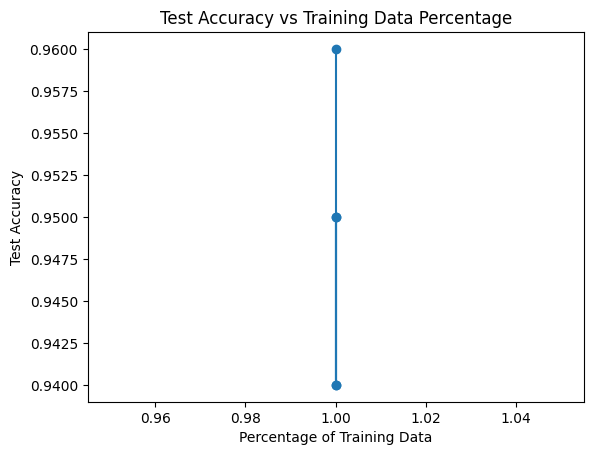

In [143]:
import matplotlib.pyplot as plt
plt.plot([1.0,1.0,1.0,1.0,1.0], [0.96,0.95,0.94,0.95,0.94],marker='o')

plt.xlabel("Percentage of Training Data")
plt.ylabel("Test Accuracy")
plt.title("Test Accuracy vs Training Data Percentage")

plt.show()

The test accuracy remains very stable between 94% and 96% for all train/test splits. Increasing the training data does not continuously increase the test accuracy

In [144]:
results = []
seeds = range(10)
for seed in seeds:
    y_pred = model.predict(X_test3)
    accuracy = accuracy_score(y_test3, y_pred)
    precision = precision_score(y_test3, y_pred)
    recall = recall_score(y_test3, y_pred)
    f1 = f1_score(y_test3, y_pred)
    results.append({
        "Seed": seed,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })
results_df = pd.DataFrame(results)
print(results_df)

   Seed  Accuracy  Precision    Recall  F1-Score
0     0      0.98   0.981982  0.981982  0.981982
1     1      0.98   0.981982  0.981982  0.981982
2     2      0.98   0.981982  0.981982  0.981982
3     3      0.98   0.981982  0.981982  0.981982
4     4      0.98   0.981982  0.981982  0.981982
5     5      0.98   0.981982  0.981982  0.981982
6     6      0.98   0.981982  0.981982  0.981982
7     7      0.98   0.981982  0.981982  0.981982
8     8      0.98   0.981982  0.981982  0.981982
9     9      0.98   0.981982  0.981982  0.981982


In [145]:
from sklearn.model_selection import cross_validate
import numpy as np
scores = cross_validate(
    model, X, y, cv=5,
    scoring=['accuracy', 'precision', 'f1']
)

for i in range(5):
    print("Fold", i+1)
    print("Accuracy:", scores['test_accuracy'][i])
    print("Precision:", scores['test_precision'][i])
    print("F1 Score:", scores['test_f1'][i])
    print("-------------------")

print("Mean Accuracy:", np.mean(scores['test_accuracy']))
print("Std Accuracy:", np.std(scores['test_accuracy']))

print("Mean F1:", np.mean(scores['test_f1']))
print("Std F1:", np.std(scores['test_f1']))

Fold 1
Accuracy: 0.975
Precision: 0.9702970297029703
F1 Score: 0.9751243781094527
-------------------
Fold 2
Accuracy: 0.97
Precision: 0.9795918367346939
F1 Score: 0.9696969696969697
-------------------
Fold 3
Accuracy: 0.97
Precision: 0.9519230769230769
F1 Score: 0.9705882352941176
-------------------
Fold 4
Accuracy: 0.945
Precision: 0.968421052631579
F1 Score: 0.9435897435897436
-------------------
Fold 5
Accuracy: 0.95
Precision: 0.96875
F1 Score: 0.9489795918367347
-------------------
Mean Accuracy: 0.962
Std Accuracy: 0.012083045973594582
Mean F1: 0.9615957837054037
Std F1: 0.012750702290528212
